# Planetary Nebula Detection with a U-Net

This notebook trains a small U-Net to detect planetary nebulae (PNe) from four synthetic emission-line images.

Expected dataset format:

- `X.shape = (N, 4, 64, 64)`
- `Y.shape = (N, 1, 64, 64)`
- channel order: `['Hbeta', 'OIII5007', 'Halpha', 'NII6584']`

The notebook converts the arrays to TensorFlow's usual channels-last format:

- `X -> (N, 64, 64, 4)`
- `Y -> (N, 64, 64, 1)`

The model predicts a PN-center heatmap with the same spatial size as the input.


## 1. Imports

In [2]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from scipy.ndimage import maximum_filter


TensorFlow version: 2.21.0


## 2. Configuration

In [3]:
# Path to your saved synthetic dataset
DATA_PATH = Path("fully_synthetic_PN_10000_norm.npz")

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Training settings
BATCH_SIZE = 32
LEARNING_RATE = 3e-4
MAX_EPOCHS = 100

# Detection settings
PEAK_THRESHOLD = 0.30
MIN_DISTANCE = 3
MATCH_TOLERANCE = 3.0   # pixels


## 3. Load the dataset

In [4]:
data = np.load(DATA_PATH, allow_pickle=True)

X = data["X"].astype(np.float32)
Y = data["Y"].astype(np.float32)

line_names = data["line_names"]
channel_means = data["channel_means"].astype(np.float32)
channel_stds = data["channel_stds"].astype(np.float32)

metadata = json.loads(data["metadata_json"].item())

print("Original X shape:", X.shape)
print("Original Y shape:", Y.shape)
print("Lines:", line_names)
print("Saved channel means:", channel_means)
print("Saved channel stds:", channel_stds)


Original X shape: (10000, 4, 64, 64)
Original Y shape: (10000, 1, 64, 64)
Lines: ['Hbeta' 'OIII5007' 'Halpha' 'NII6584']
Saved channel means: [9.6350442e-19 7.1393897e-19 3.6404438e-18 1.9487250e-18]
Saved channel stds: [7.3488618e-19 1.1068283e-18 3.2730697e-18 1.9099968e-18]


## 4. Convert from channels-first to channels-last

Your saved arrays use:

```text
X: (N, C, H, W)
Y: (N, 1, H, W)
```

TensorFlow/Keras is simplest with:

```text
X: (N, H, W, C)
Y: (N, H, W, 1)
```


In [5]:
# (N, C, H, W) -> (N, H, W, C)
X = np.transpose(X, (0, 2, 3, 1))

# (N, 1, H, W) -> (N, H, W, 1)
Y = np.transpose(Y, (0, 2, 3, 1))

print("Transposed X shape:", X.shape)
print("Transposed Y shape:", Y.shape)

assert X.ndim == 4 and X.shape[-1] == 4
assert Y.ndim == 4 and Y.shape[-1] == 1
assert X.shape[1:3] == (64, 64)
assert Y.shape[1:3] == (64, 64)


Transposed X shape: (10000, 64, 64, 4)
Transposed Y shape: (10000, 64, 64, 1)


## 5. Inspect normalization before changing anything

In [6]:
current_means = X.mean(axis=(0, 1, 2))
current_stds = X.std(axis=(0, 1, 2))

print("Current X means:", current_means)
print("Current X stds :", current_stds)

already_standardized = (
    np.all(np.abs(current_means) < 0.1)
    and np.all(np.abs(current_stds - 1.0) < 0.1)
)

print("Looks already standardized:", already_standardized)


Current X means: [-9.3698498e-09  7.5399875e-10 -2.1934510e-09  3.2037498e-10]
Current X stds : [1.000001  0.999999  1.0000005 1.0000014]
Looks already standardized: True


## 6. Normalize the four input channels

If the saved `X` is already standardized, the cell below leaves it unchanged.

Otherwise it uses the `channel_means` and `channel_stds` stored in your `.npz` file.

Keep these same training-set means and standard deviations when you later apply the model to real MUSE maps.


In [7]:
if already_standardized:
    print("X is already approximately standardized. No additional normalization applied.")
else:
    X = (
        X - channel_means[None, None, None, :]
    ) / (
        channel_stds[None, None, None, :] + 1e-8
    )

print("Final means:", X.mean(axis=(0, 1, 2)))
print("Final stds :", X.std(axis=(0, 1, 2)))


X is already approximately standardized. No additional normalization applied.
Final means: [-9.3698498e-09  7.5399875e-10 -2.1934510e-09  3.2037498e-10]
Final stds : [1.000001  0.999999  1.0000005 1.0000014]


## 7. Inspect a few input channels and the target

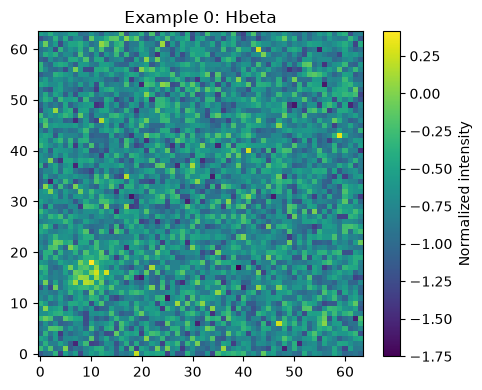

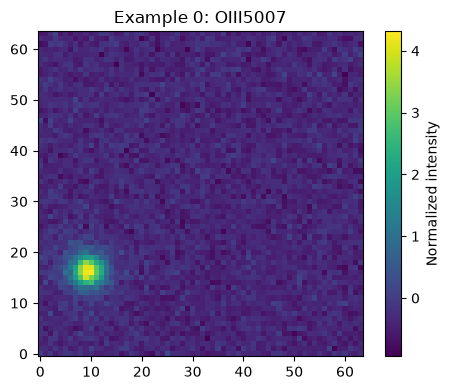

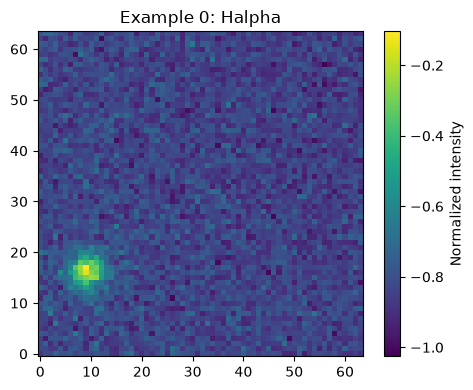

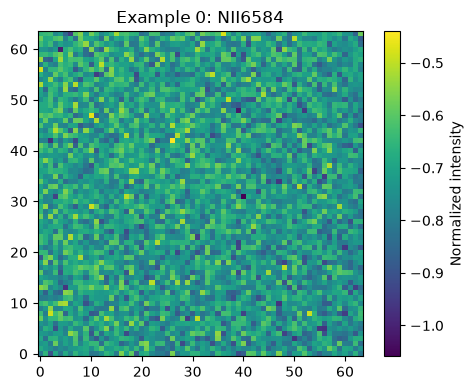

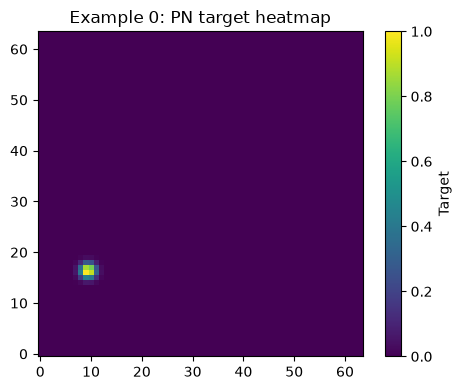

In [8]:
i = 0

for c, name in enumerate(line_names):
    plt.figure(figsize=(5, 4))
    plt.imshow(X[i, :, :, c], origin="lower")
    plt.colorbar(label="Normalized intensity")
    plt.title(f"Example {i}: {name}")
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(5, 4))
plt.imshow(Y[i, :, :, 0], origin="lower")
plt.colorbar(label="Target")
plt.title(f"Example {i}: PN target heatmap")
plt.tight_layout()
plt.show()


## 8. Train / validation / test split

In [9]:
X_train, X_temp, Y_train, Y_temp = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=SEED
)

X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp,
    Y_temp,
    test_size=0.50,
    random_state=SEED
)

print("Train:", X_train.shape, Y_train.shape)
print("Val  :", X_val.shape, Y_val.shape)
print("Test :", X_test.shape, Y_test.shape)


Train: (8000, 64, 64, 4) (8000, 64, 64, 1)
Val  : (1000, 64, 64, 4) (1000, 64, 64, 1)
Test : (1000, 64, 64, 4) (1000, 64, 64, 1)


## 9. Data augmentation

Only spatial transformations are used here. The same transformation is applied to the four input channels and the target heatmap.


In [10]:
def augment(x, y):
    # Random 0, 90, 180 or 270 degree rotation
    k = tf.random.uniform(
        shape=[],
        minval=0,
        maxval=4,
        dtype=tf.int32
    )

    x = tf.image.rot90(x, k)
    y = tf.image.rot90(y, k)

    # Horizontal flip
    do_lr = tf.random.uniform([]) > 0.5
    x = tf.cond(do_lr, lambda: tf.image.flip_left_right(x), lambda: x)
    y = tf.cond(do_lr, lambda: tf.image.flip_left_right(y), lambda: y)

    # Vertical flip
    do_ud = tf.random.uniform([]) > 0.5
    x = tf.cond(do_ud, lambda: tf.image.flip_up_down(x), lambda: x)
    y = tf.cond(do_ud, lambda: tf.image.flip_up_down(y), lambda: y)

    return x, y


## 10. Build TensorFlow datasets

In [11]:
train_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_train, Y_train))
    .shuffle(len(X_train), seed=SEED)
    .map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_val, Y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_test, Y_test))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


I0000 00:00:1787127058.009610    1149 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5518 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


## 11. Small U-Net

In [12]:
def conv_block(x, filters):
    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_initializer="he_normal"
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    return x


def build_unet(input_shape=(64, 64, 4)):
    inputs = keras.Input(shape=input_shape)

    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    # Bottleneck
    b = conv_block(p3, 256)
    b = layers.Dropout(0.20)(b)

    # Decoder
    u3 = layers.Conv2DTranspose(
        128, kernel_size=2, strides=2, padding="same"
    )(b)
    u3 = layers.Concatenate()([u3, c3])
    c4 = conv_block(u3, 128)

    u2 = layers.Conv2DTranspose(
        64, kernel_size=2, strides=2, padding="same"
    )(c4)
    u2 = layers.Concatenate()([u2, c2])
    c5 = conv_block(u2, 64)

    u1 = layers.Conv2DTranspose(
        32, kernel_size=2, strides=2, padding="same"
    )(c5)
    u1 = layers.Concatenate()([u1, c1])
    c6 = conv_block(u1, 32)

    outputs = layers.Conv2D(
        1,
        kernel_size=1,
        activation="sigmoid",
        name="pn_heatmap"
    )(c6)

    return keras.Model(inputs, outputs, name="PN_UNet")


model = build_unet()
model.summary()


Model: "PN_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 4) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │      1,152 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      9,216 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     18,432 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │     36,864 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     73,728 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_4[0][0]  

 Total params: 1,930,113 (7.36 MB)

 Trainable params: 1,927,297 (7.35 MB)

 Non-trainable params: 2,816 (11.00 KB)

## 12. Center heatmap focal loss

This is useful because almost all pixels are background.

It assumes the center of a true PN reaches a target value very close to `1.0`, while nearby pixels can contain a Gaussian-like soft target.


In [13]:
@tf.keras.utils.register_keras_serializable()
def center_focal_loss(y_true, y_pred):
    eps = 1e-6

    y_pred = tf.clip_by_value(
        y_pred,
        eps,
        1.0 - eps
    )

    # PN center pixels
    positive = tf.cast(y_true >= 0.999, tf.float32)

    # All other pixels
    negative = tf.cast(y_true < 0.999, tf.float32)

    # Nearby Gaussian pixels are penalized less than distant background
    negative_weights = tf.pow(1.0 - y_true, 4.0)

    positive_loss = (
        -tf.math.log(y_pred)
        * tf.pow(1.0 - y_pred, 2.0)
        * positive
    )

    negative_loss = (
        -tf.math.log(1.0 - y_pred)
        * tf.pow(y_pred, 2.0)
        * negative_weights
        * negative
    )

    num_positive = tf.reduce_sum(positive)

    total_loss = (
        tf.reduce_sum(positive_loss)
        + tf.reduce_sum(negative_loss)
    )

    return tf.cond(
        num_positive > 0,
        lambda: total_loss / num_positive,
        lambda: total_loss
    )


## 13. Compile the model

In [14]:
'''
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=center_focal_loss
)
'''
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=keras.losses.BinaryCrossentropy()
)

## 14. Training callbacks

In [15]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_PN_UNet.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    )
]


## 15. Train

In [16]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS,
    callbacks=callbacks
)


Epoch 1/100


/home/sina/miniconda3/envs/master_thesis/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1787127063.348022   31331 service.cc:153] XLA service 0x78d06c04e4d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1787127063.348096   31331 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4070 Laptop GPU, Compute Capability 8.9 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.9.0; DNN: 9.23.1)
I0000 00:00:1787127063.460116   31331 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1787127064.025776   31331 cuda_dnn.cc:461] Loaded cuDNN version 92301
I0000 00:00:1787127077.777507   31331 devi

248/250 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.1346
Epoch 1: val_loss improved from None to 0.07128, saving model to best_PN_UNet.keras

Epoch 1: finished saving model to best_PN_UNet.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 26s 35ms/step - loss: 0.1340 - val_loss: 0.0713 - learning_rate: 3.0000e-04
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0452
Epoch 2: val_loss improved from 0.07128 to 0.03090, saving model to best_PN_UNet.keras

Epoch 2: finished saving model to best_PN_UNet.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0452 - val_loss: 0.0309 - learning_rate: 3.0000e-04
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0251
Epoch 3: val_loss improved from 0.03090 to 0.01746, saving model to best_PN_UNet.keras

Epoch 3: finished saving model to best_PN_UNet.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0251 - val_loss: 0.0175 - learning_rate: 3.0000e-04
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0166
Epo

## 16. Plot the training history

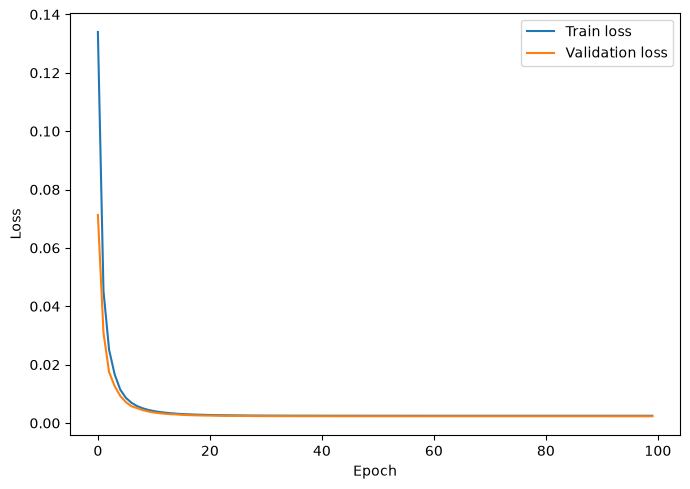

In [17]:
plt.figure(figsize=(7, 5))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()


## 17. Evaluate test loss

In [18]:
test_loss = model.evaluate(test_ds, verbose=1)
print("Test loss:", test_loss)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0025
Test loss: 0.002477011177688837


## 18. Predict one example

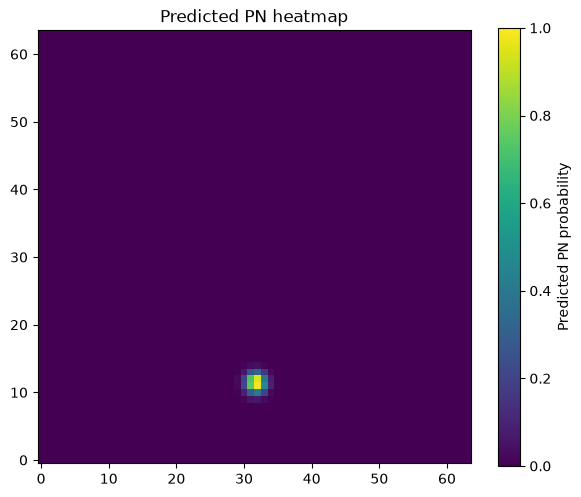

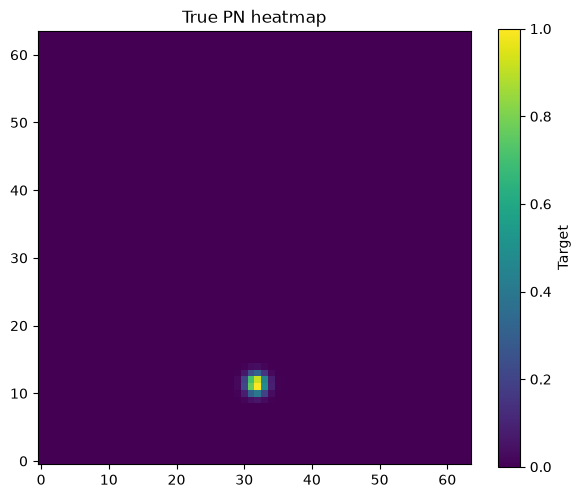

In [19]:
i = 60

pred = model.predict(
    X_test[i:i+1],
    verbose=0
)[0, :, :, 0]

truth = Y_test[i, :, :, 0]

plt.figure(figsize=(6, 5))
plt.imshow(pred, origin="lower", vmin=0, vmax=1)
plt.colorbar(label="Predicted PN probability")
plt.title("Predicted PN heatmap")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
plt.imshow(truth, origin="lower", vmin=0, vmax=1)
plt.colorbar(label="Target")
plt.title("True PN heatmap")
plt.tight_layout()
plt.show()


## 19. Find PN centers from a predicted heatmap

In [20]:
def find_pn_centers(
    heatmap,
    threshold=0.30,
    min_distance=3
):
    size = 2 * min_distance + 1

    local_max = (
        heatmap
        == maximum_filter(
            heatmap,
            size=size,
            mode="constant"
        )
    )

    detected = local_max & (heatmap >= threshold)

    y, x = np.where(detected)
    scores = heatmap[y, x]

    order = np.argsort(scores)[::-1]

    return np.column_stack(
        [x[order], y[order], scores[order]]
    )


detections = find_pn_centers(
    pred,
    threshold=PEAK_THRESHOLD,
    min_distance=MIN_DISTANCE
)

print("Detected PN centers [x, y, score]:")
print(detections)


Detected PN centers [x, y, score]:
[[32.        11.         0.9811815]]


## 20. Plot detections over the predicted heatmap

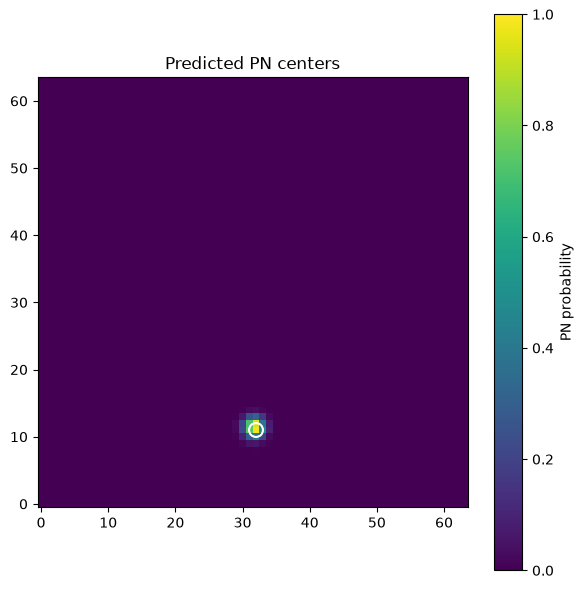

In [21]:
plt.figure(figsize=(6, 6))
plt.imshow(pred, origin="lower", vmin=0, vmax=1)
plt.colorbar(label="PN probability")

if len(detections) > 0:
    plt.scatter(
        detections[:, 0],
        detections[:, 1],
        facecolors="none",
        edgecolors="white",
        s=100,
        linewidths=1.5
    )

plt.title("Predicted PN centers")
plt.tight_layout()
plt.show()


## 21. Extract true PN centers from the target heatmap

For the evaluation below, a PN center is taken to be a local maximum with target value close to 1.


In [22]:
def find_true_centers(
    target,
    threshold=0.999,
    min_distance=1
):
    size = 2 * min_distance + 1

    local_max = (
        target
        == maximum_filter(
            target,
            size=size,
            mode="constant"
        )
    )

    detected = local_max & (target >= threshold)

    y, x = np.where(detected)

    return np.column_stack([x, y]).astype(np.float32)


## 22. Match predicted detections to true PNe

A predicted PN is considered correct if it lies within `MATCH_TOLERANCE` pixels of an unmatched true PN.


In [23]:
def match_detections(
    predicted,
    true_centers,
    tolerance=3.0
):
    if len(predicted) == 0:
        return 0, 0, len(true_centers), []

    if len(true_centers) == 0:
        return 0, len(predicted), 0, []

    pred_xy = np.asarray(predicted[:, :2], dtype=np.float32)
    true_xy = np.asarray(true_centers, dtype=np.float32)

    used_true = set()

    tp = 0
    localization_errors = []

    # Predictions are already sorted by confidence
    for px, py in pred_xy:

        distances = np.sqrt(
            (true_xy[:, 0] - px)**2
            + (true_xy[:, 1] - py)**2
        )

        order = np.argsort(distances)

        for j in order:

            if distances[j] > tolerance:
                break

            if j not in used_true:
                used_true.add(j)

                tp += 1

                # Save localization error for this TP
                localization_errors.append(
                    distances[j]
                )

                break

    fp = len(pred_xy) - tp
    fn = len(true_xy) - tp

    return tp, fp, fn, localization_errors

## 23. Source-level precision and recall on the full test set

In [24]:
def evaluate_detector(
    model,
    X_test,
    Y_test,
    threshold=0.30,
    min_distance=3,
    match_tolerance=3.0
):

    predictions = model.predict(
        X_test,
        verbose=1
    )

    total_tp = 0
    total_fp = 0
    total_fn = 0

    all_localization_errors = []

    for pred_map, true_map in zip(
        predictions,
        Y_test
    ):

        pred_centers = find_pn_centers(
            pred_map[:, :, 0],
            threshold=threshold,
            min_distance=min_distance
        )

        true_centers = find_true_centers(
            true_map[:, :, 0]
        )

        tp, fp, fn, errors = match_detections(
            pred_centers,
            true_centers,
            tolerance=match_tolerance
        )

        total_tp += tp
        total_fp += fp
        total_fn += fn

        all_localization_errors.extend(errors)

    precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp > 0
        else 0.0
    )

    recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn > 0
        else 0.0
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if precision + recall > 0
        else 0.0
    )

    errors = np.asarray(
        all_localization_errors
    )

    if len(errors) > 0:

        mean_error = np.mean(errors)

        median_error = np.median(errors)

        rmse_error = np.sqrt(
            np.mean(errors**2)
        )

        std_error = np.std(errors)

    else:

        mean_error = np.nan
        median_error = np.nan
        rmse_error = np.nan
        std_error = np.nan

    return {
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,

        "precision": precision,
        "recall": recall,
        "f1": f1,

        "mean_localization_error": mean_error,
        "median_localization_error": median_error,
        "rmse_localization_error": rmse_error,
        "std_localization_error": std_error,

        "localization_errors": errors
    }

## 24. Tune the detection threshold on the validation set

Do **not** choose the final threshold from the test set.

This cell scans a small threshold grid using the validation set and reports source-level precision, recall and F1.


In [25]:
thresholds = np.arange(0.10, 0.91, 0.10)

results = []

for threshold in thresholds:
    m = evaluate_detector(
        model,
        X_val,
        Y_val,
        threshold=float(threshold),
        min_distance=MIN_DISTANCE,
        match_tolerance=MATCH_TOLERANCE
    )

    results.append([
        threshold,
        m["precision"],
        m["recall"],
        m["f1"]
    ])

results = np.asarray(results)

print("threshold   precision   recall   F1")
for row in results:
    print(
        f"{row[0]:.2f}        "
        f"{row[1]:.3f}       "
        f"{row[2]:.3f}    "
        f"{row[3]:.3f}"
    )

best_index = np.argmax(results[:, 3])
best_threshold = results[best_index, 0]

print("\nBest validation threshold:", best_threshold)


32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
threshold   precision   recall   F1
0.10        1.000       1.000    1.000
0.20        1.000       1.000    1.000
0.30        1.000       1.000    1.000
0.40        1.000       1.000    1.000
0.50        1.000       1.000    1.000
0.60        1.000       1.000    1.000
0.70        1.000       1.000    1.000
0.80        1.000       0.999    0.999
0.90        1.000       0.996    0.998

Best validation threshold: 0.1


## 25. Plot threshold dependence

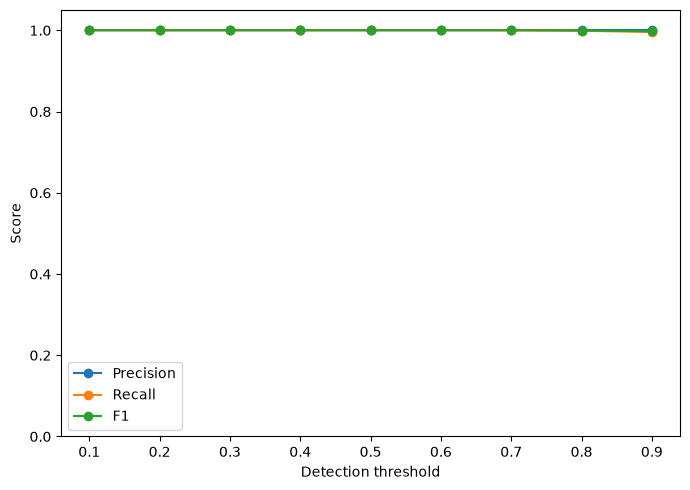

In [26]:
plt.figure(figsize=(7, 5))
plt.plot(results[:, 0], results[:, 1], marker="o", label="Precision")
plt.plot(results[:, 0], results[:, 2], marker="o", label="Recall")
plt.plot(results[:, 0], results[:, 3], marker="o", label="F1")
plt.xlabel("Detection threshold")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()


## 26. Final source-level test metrics using the validation-selected threshold

In [27]:
final_metrics = evaluate_detector(
    model,
    X_test,
    Y_test,
    threshold=float(best_threshold),
    min_distance=MIN_DISTANCE,
    match_tolerance=MATCH_TOLERANCE
)

print("Final test metrics:")
for key, value in final_metrics.items():
    print(f"{key}: {value}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Final test metrics:
TP: 981
FP: 0
FN: 0
precision: 1.0
recall: 1.0
f1: 1.0
mean_localization_error: 0.07406406849622726
median_localization_error: 0.0
rmse_localization_error: 0.2765006422996521
std_localization_error: 0.26639652252197266
localization_errors: [0.        0.        0.        0.        0.        0.        0.
 0.        0.        0.        0.        0.        0.        0.
 0.        0.        0.        0.        0.        0.        0.
 0.        0.        0.        0.        0.        0.        0.
 1.4142135 0.        0.        0.        0.        0.        0.
 0.        0.        0.        0.        0.        0.        0.
 0.        0.        0.        0.        0.        0.        0.
 0.        0.        0.        0.        0.        0.        0.
 0.        0.        0.        0.        0.        1.        1.
 0.        1.        0.        0.        0.        0.        0.
 0.        0.        0.        0.        0.        0.        

## 27. Save useful normalization information

These values should be reused when preparing real MUSE emission-line maps for inference.


In [28]:
np.savez(
    "PN_UNet_normalization.npz",
    line_names=np.asarray(line_names),
    channel_means=np.asarray(channel_means),
    channel_stds=np.asarray(channel_stds)
)

print("Saved normalization information.")


Saved normalization information.


## Notes

- The four channels remain in the order:
  1. `Hbeta`
  2. `OIII5007`
  3. `Halpha`
  4. `NII6584`

- Pixel-wise accuracy is **not** a useful metric here because almost all pixels are background.

- The scientifically useful metrics are source-level:
  - completeness / recall
  - purity / precision
  - F1
  - localization error
  - completeness versus PN flux/SNR and local background

- The center focal loss assumes that each target PN has at least one pixel with value approximately `1.0`.
  If your `Y` targets use a different convention, modify the positive-pixel definition accordingly.
